# TP2: French Medical Named Entity Recognition

This notebook adapts the instructor's LSTM/CNN sequence-classification script to token-level NER and adapts the Transformer classification script to BERT token classification. It compares six existing TP1 static embeddings with a multilingual BERT baseline on the combined EMEA + MEDLINE medical corpus.

Static systems: 6 embeddings x {LSTM, CNN} = 12 runs. For each embedding, the architecture with the best development entity-level F1 is selected. BERT uses the best development epoch. The test set is evaluated only after these selections.

In [1]:
%pip install -q seqeval transformers sentencepiece


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 1. Setup and Data

In [ ]:
import copy
import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from gensim.models import Word2Vec
from gensim.models.fasttext import load_facebook_vectors
from gensim.models.keyedvectors import KeyedVectors
try:
    from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
    from seqeval.scheme import IOB2
except ImportError:
    class IOB2:
        pass

    def _entities(tags, sentence_id):
        entities, active = set(), None
        for index, tag in enumerate(tags + ['O']):
            if tag.startswith('B-'):
                if active is not None:
                    entities.add((sentence_id, *active))
                active = (tag[2:], index, index + 1)
            elif tag.startswith('I-') and active is not None and active[0] == tag[2:]:
                active = (active[0], active[1], index + 1)
            else:
                if active is not None:
                    entities.add((sentence_id, *active))
                active = None
        return entities

    def _scores(true_sequences, pred_sequences):
        true_entities = set().union(*[_entities(tags, i) for i, tags in enumerate(true_sequences)])
        pred_entities = set().union(*[_entities(tags, i) for i, tags in enumerate(pred_sequences)])
        tp = len(true_entities & pred_entities)
        precision = tp / len(pred_entities) if pred_entities else 0.0
        recall = tp / len(true_entities) if true_entities else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        return precision, recall, f1

    def precision_score(true_sequences, pred_sequences, **kwargs):
        return _scores(true_sequences, pred_sequences)[0]

    def recall_score(true_sequences, pred_sequences, **kwargs):
        return _scores(true_sequences, pred_sequences)[1]

    def f1_score(true_sequences, pred_sequences, **kwargs):
        return _scores(true_sequences, pred_sequences)[2]

    def classification_report(true_sequences, pred_sequences, output_dict=False, **kwargs):
        labels = sorted({entity[1] for sentence_id, tags in enumerate(true_sequences + pred_sequences) for entity in _entities(tags, sentence_id)})
        report = {}
        for label in labels:
            true_entities = {(sentence_id, kind, start, end) for sentence_id, tags in enumerate(true_sequences) for _, kind, start, end in _entities(tags, sentence_id) if kind == label}
            pred_entities = {(sentence_id, kind, start, end) for sentence_id, tags in enumerate(pred_sequences) for _, kind, start, end in _entities(tags, sentence_id) if kind == label}
            tp = len(true_entities & pred_entities)
            precision = tp / len(pred_entities) if pred_entities else 0.0
            recall = tp / len(true_entities) if true_entities else 0.0
            f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
            report[label] = {'precision': precision, 'recall': recall, 'f1-score': f1}
        return report if output_dict else ''
from torch import nn
from torch.nn import functional as F
from torch.optim import Adam, AdamW
from torch.utils.data import DataLoader, Dataset
from transformers import AutoModelForTokenClassification, AutoTokenizer

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
DEVICE = torch.device('cpu')

ROOT = Path('.')
EMBEDDING_DIR = ROOT / 'models_word_vectors'
NER_ROOT = ROOT / 'TP_ISD2020/QUAERO_FrenchMed'
OUTPUT_DIR = ROOT / 'tp2_ner_outputs'
OUTPUT_DIR.mkdir(exist_ok=True)

EMBEDDING_PATHS = {
    'Medical Word2Vec CBOW': EMBEDDING_DIR / 'med_word2vec_cbow.model',
    'Medical Word2Vec Skip-gram': EMBEDDING_DIR / 'med_word2vec_skipgram.model',
    'Medical FastText CBOW': EMBEDDING_DIR / 'med_fasttext_cbow.bin',
    'Press Word2Vec CBOW': EMBEDDING_DIR / 'press_word2vec_cbow.model',
    'Press Word2Vec Skip-gram': EMBEDDING_DIR / 'press_word2vec_skipgram.model',
    'Press FastText CBOW': EMBEDDING_DIR / 'press_fasttext_cbow.bin',
}

def load_conll(path):
    sentences = []
    current = []
    for line in Path(path).read_text(encoding='utf-8').splitlines():
        if not line.strip():
            if current:
                sentences.append(current)
                current = []
            continue
        fields = line.split()
        current.append((fields[1], fields[-1]))
    if current:
        sentences.append(current)
    return sentences

def load_split(split):
    sentences = []
    for source in ['EMEA', 'MEDLINE']:
        sentences.extend(load_conll(NER_ROOT / source / f'{source}{split}_layer1_ID.conll'))
    return sentences

splits = {split: load_split(split) for split in ['train', 'dev', 'test']}
train_sentences = [[token for token, _ in sentence] for sentence in splits['train']]
label_names = sorted({tag for sentence in splits['train'] for _, tag in sentence}, key=lambda tag: (tag != 'O', tag))
label2id = {label: i for i, label in enumerate(label_names)}
id2label = {i: label for label, i in label2id.items()}

dataset_summary = pd.DataFrame([
    {
        'Split': split,
        'Sentences': len(sentences),
        'Tokens': sum(len(sentence) for sentence in sentences),
    }
    for split, sentences in splits.items()
])
display(dataset_summary)
print(f'Labels: {len(label_names)} | Device: {DEVICE}')

,Split,Sentences,Tokens
0,train,1540,26864
1,dev,1481,25032
2,test,1413,24296


Labels: 21 | Device: cpu


## 2. Label Distribution

The same combined medical train/dev/test splits are used for every system.

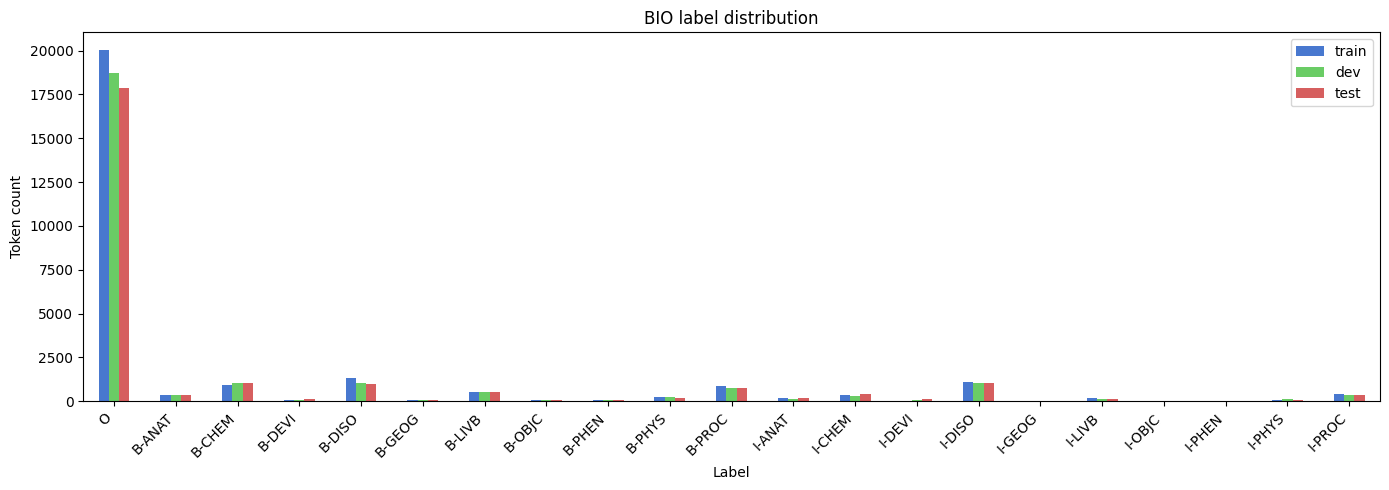

In [3]:
label_counts = pd.DataFrame({
    split: pd.Series([tag for sentence in sentences for _, tag in sentence]).value_counts()
    for split, sentences in splits.items()
}).fillna(0).astype(int).reindex(label_names)
label_counts.plot(kind='bar', figsize=(14, 5), color=['#4878CF', '#6ACC65', '#D65F5F'])
plt.title('BIO label distribution')
plt.xlabel('Label')
plt.ylabel('Token count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 3. Adapted Static NER Models

The instructor's sentiment LSTM is changed from one sentence output to one output per timestep. The instructor's CNN keeps its convolutional feature extraction, but uses same-length token features instead of global sentence pooling. Both models use token-level `CrossEntropyLoss` with padded labels ignored.

All six TP1 models are loaded through the same `KeyedVectors` interface. Word2Vec models use their `.wv`; FastText binaries are loaded with Gensim's Facebook-vector loader. No embedding is retrained.

In [4]:
PAD_TOKEN = '<PAD>'
UNK_TOKEN = '<UNK>'
word2id = {PAD_TOKEN: 0, UNK_TOKEN: 1}
for token in sorted({token for sentence in train_sentences for token in sentence}):
    word2id[token] = len(word2id)
pad_id = word2id[PAD_TOKEN]
unk_id = word2id[UNK_TOKEN]

def load_keyed_vectors(path):
    path = Path(path)
    if path.suffix == '.model':
        return Word2Vec.load(str(path)).wv
    return load_facebook_vectors(str(path))

def build_embedding_matrix(keyed_vectors):
    rng = np.random.default_rng(SEED)
    matrix = rng.normal(0, 0.05, size=(len(word2id), keyed_vectors.vector_size)).astype('float32')
    matrix[pad_id] = 0.0
    covered = 0
    for token, index in word2id.items():
        if token in {PAD_TOKEN, UNK_TOKEN}:
            continue
        if token in keyed_vectors:
            matrix[index] = keyed_vectors[token]
            covered += 1
    return matrix, covered

class StaticNERDataset(Dataset):
    def __init__(self, sentences):
        self.sentences = sentences

    def __len__(self):
        return len(self.sentences)

    def __getitem__(self, index):
        sentence = self.sentences[index]
        token_ids = [word2id.get(token, unk_id) for token, _ in sentence]
        tag_ids = [label2id[tag] for _, tag in sentence]
        return torch.tensor(token_ids), torch.tensor(tag_ids)

def collate_static(batch):
    max_len = max(len(token_ids) for token_ids, _ in batch)
    token_batch = torch.full((len(batch), max_len), pad_id, dtype=torch.long)
    label_batch = torch.full((len(batch), max_len), -100, dtype=torch.long)
    for row, (token_ids, tag_ids) in enumerate(batch):
        token_batch[row, :len(token_ids)] = token_ids
        label_batch[row, :len(tag_ids)] = tag_ids
    return token_batch, label_batch

train_loader = DataLoader(StaticNERDataset(splits['train']), batch_size=32, shuffle=True, collate_fn=collate_static)
dev_loader = DataLoader(StaticNERDataset(splits['dev']), batch_size=32, shuffle=False, collate_fn=collate_static)
test_loader = DataLoader(StaticNERDataset(splits['test']), batch_size=32, shuffle=False, collate_fn=collate_static)

class TokenLSTMTagger(nn.Module):
    def __init__(self, embedding_matrix, num_labels, hidden_size=96, layers=1, dropout=0.25):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(torch.tensor(embedding_matrix), freeze=True, padding_idx=pad_id)
        self.lstm = nn.LSTM(embedding_matrix.shape[1], hidden_size, layers, batch_first=True, bidirectional=True, dropout=0.0)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size * 2, num_labels)

    def forward(self, token_ids):
        sequence, _ = self.lstm(self.embedding(token_ids))
        return self.classifier(self.dropout(sequence))

class TokenCNNTagger(nn.Module):
    def __init__(self, embedding_matrix, num_labels, channels=64, dropout=0.25):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(torch.tensor(embedding_matrix), freeze=True, padding_idx=pad_id)
        self.convs = nn.ModuleList([nn.Conv2d(1, channels, (kernel, embedding_matrix.shape[1]), padding=(kernel // 2, 0)) for kernel in [3, 4, 5]])
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(channels * 3, num_labels)

    def forward(self, token_ids):
        embedded = self.embedding(token_ids).unsqueeze(1)
        time_steps = token_ids.size(1)
        features = [F.relu(conv(embedded)).squeeze(3)[:, :, :time_steps] for conv in self.convs]
        sequence = torch.cat(features, dim=1).transpose(1, 2)
        return self.classifier(self.dropout(sequence))

def seqeval_metrics(true_sequences, pred_sequences):
    return {
        'Precision': precision_score(true_sequences, pred_sequences, mode='strict', scheme=IOB2),
        'Recall': recall_score(true_sequences, pred_sequences, mode='strict', scheme=IOB2),
        'F1': f1_score(true_sequences, pred_sequences, mode='strict', scheme=IOB2),
    }

def decode_static(logits, labels):
    predictions = logits.argmax(dim=-1)
    true_sequences, pred_sequences = [], []
    for row in range(labels.size(0)):
        mask = labels[row] != -100
        true_sequences.append([id2label[int(value)] for value in labels[row][mask]])
        pred_sequences.append([id2label[int(value)] for value in predictions[row][mask]])
    return true_sequences, pred_sequences

def evaluate_static(model, loader):
    model.eval()
    criterion = nn.CrossEntropyLoss(ignore_index=-100)
    total_loss = 0.0
    true_sequences, pred_sequences = [], []
    with torch.no_grad():
        for token_ids, labels in loader:
            logits = model(token_ids.to(DEVICE))
            total_loss += criterion(logits.reshape(-1, len(label_names)), labels.to(DEVICE).reshape(-1)).item()
            true_batch, pred_batch = decode_static(logits.cpu(), labels)
            true_sequences.extend(true_batch)
            pred_sequences.extend(pred_batch)
    metrics = seqeval_metrics(true_sequences, pred_sequences)
    metrics['Loss'] = total_loss / len(loader)
    return metrics, true_sequences, pred_sequences

def train_static(model, epochs=3, patience=1, learning_rate=2e-3):
    criterion = nn.CrossEntropyLoss(ignore_index=-100)
    optimizer = Adam((parameter for parameter in model.parameters() if parameter.requires_grad), lr=learning_rate)
    best_state, best_dev = copy.deepcopy(model.state_dict()), {'F1': -1.0}
    history, stale = [], 0
    model.to(DEVICE)
    for epoch in range(1, epochs + 1):
        model.train()
        train_loss = 0.0
        for token_ids, labels in train_loader:
            optimizer.zero_grad()
            logits = model(token_ids.to(DEVICE))
            loss = criterion(logits.reshape(-1, len(label_names)), labels.to(DEVICE).reshape(-1))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimizer.step()
            train_loss += loss.item()
        dev_metrics, _, _ = evaluate_static(model, dev_loader)
        row = {'Epoch': epoch, 'Train loss': train_loss / len(train_loader), **{f'Dev {key}': value for key, value in dev_metrics.items()}}
        history.append(row)
        if dev_metrics['F1'] > best_dev['F1']:
            best_dev = dev_metrics
            best_state = copy.deepcopy(model.state_dict())
            stale = 0
        else:
            stale += 1
            if stale >= patience:
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_dev


## 4. Train 12 Static Runs and Select by Development F1

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/seqeval/metrics/v1.py:57: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/seqeval/metrics/v1.py:57: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/seqeval/metrics/v1.py:57: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Library/Frameworks/Python.framework/Versions/3.12/l

,Embedding,Dimension,Train vocabulary coverage
0,Medical Word2Vec CBOW,100,100.0%
1,Medical Word2Vec Skip-gram,100,100.0%
2,Medical FastText CBOW,100,100.0%
3,Press Word2Vec CBOW,100,46.3%
4,Press Word2Vec Skip-gram,100,46.3%
5,Press FastText CBOW,100,100.0%


,Embedding,Source corpus,Architecture,Dev Precision,Dev Recall,Dev F1,Dev Loss
0,Medical FastText CBOW,Medical,CNN,0.056738,0.001933,0.003739,1.275666
1,Medical FastText CBOW,Medical,LSTM,0.000000,0.000000,0.000000,1.187349
2,Medical Word2Vec CBOW,Medical,CNN,0.500000,0.000242,0.000483,1.120213
3,Medical Word2Vec CBOW,Medical,LSTM,0.000000,0.000000,0.000000,1.108700
4,Medical Word2Vec Skip-gram,Medical,CNN,0.214540,0.072740,0.108645,1.057499
5,Medical Word2Vec Skip-gram,Medical,LSTM,0.000000,0.000000,0.000000,1.193886
6,Press FastText CBOW,Press,CNN,0.383742,0.204205,0.266562,0.955848
7,Press FastText CBOW,Press,LSTM,0.387963,0.202513,0.266116,0.890413
8,Press Word2Vec CBOW,Press,CNN,0.330265,0.138714,0.195371,0.946969
9,Press Word2Vec CBOW,Press,LSTM,0.287476,0.146448,0.194044,0.936810


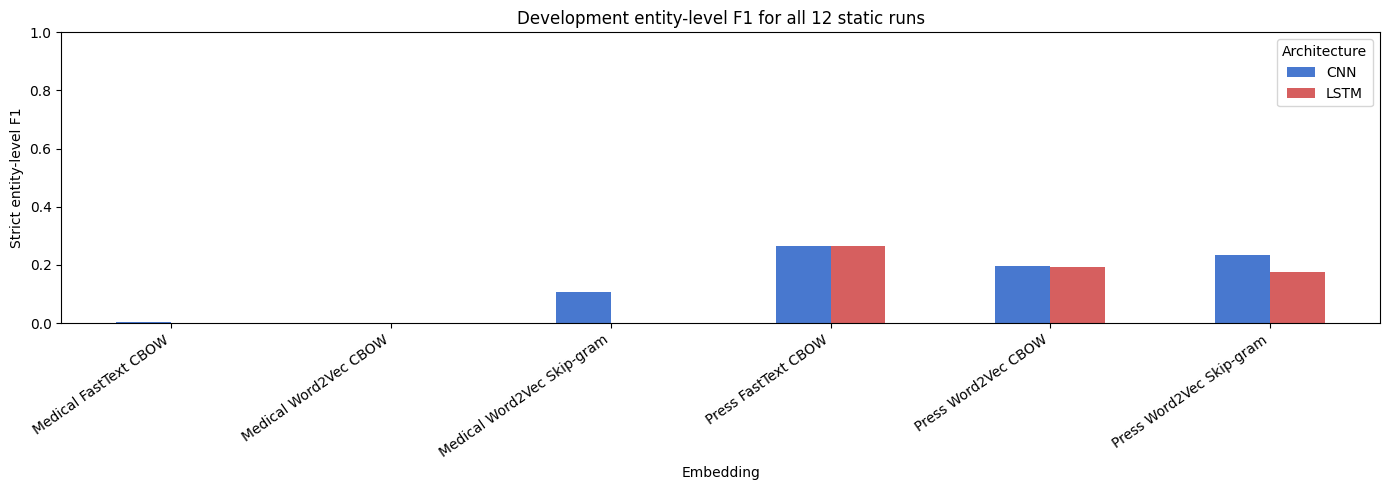

,Embedding,Source corpus,Representation,Architecture,Dev Precision,Dev Recall,Dev F1,Dev Loss
0,Press FastText CBOW,Press,FastText CBOW,CNN,0.383742,0.204205,0.266562,0.955848
1,Press Word2Vec Skip-gram,Press,Word2Vec Skip-gram,CNN,0.401417,0.164331,0.233196,0.932403
2,Press Word2Vec CBOW,Press,Word2Vec CBOW,CNN,0.330265,0.138714,0.195371,0.946969
3,Medical Word2Vec Skip-gram,Medical,Word2Vec Skip-gram,CNN,0.214540,0.072740,0.108645,1.057499
4,Medical FastText CBOW,Medical,FastText CBOW,CNN,0.056738,0.001933,0.003739,1.275666
5,Medical Word2Vec CBOW,Medical,Word2Vec CBOW,CNN,0.500000,0.000242,0.000483,1.120213


In [5]:
static_runs = []
coverage_rows = []
for embedding_name, embedding_path in EMBEDDING_PATHS.items():
    keyed_vectors = load_keyed_vectors(embedding_path)
    embedding_matrix, covered = build_embedding_matrix(keyed_vectors)
    coverage_rows.append({
        'Embedding': embedding_name,
        'Dimension': keyed_vectors.vector_size,
        'Train vocabulary coverage': covered / (len(word2id) - 2),
    })
    for architecture, model_class in [('LSTM', TokenLSTMTagger), ('CNN', TokenCNNTagger)]:
        model = model_class(embedding_matrix, len(label_names))
        model, history, dev_metrics = train_static(model)
        static_runs.append({
            'Embedding': embedding_name,
            'Source corpus': 'Medical' if embedding_name.startswith('Medical') else 'Press',
            'Representation': embedding_name.split(' ', 1)[1],
            'Architecture': architecture,
            'Model': model,
            'History': history,
            **{f'Dev {key}': value for key, value in dev_metrics.items()},
        })

coverage_df = pd.DataFrame(coverage_rows)
dev_architecture_df = pd.DataFrame([{key: value for key, value in run.items() if key.startswith('Dev') or key in ['Embedding', 'Source corpus', 'Architecture']} for run in static_runs])
display(coverage_df.style.format({'Train vocabulary coverage': '{:.1%}'}))
display(dev_architecture_df.sort_values(['Embedding', 'Dev F1'], ascending=[True, False]).reset_index(drop=True))

dev_architecture_df.pivot(index='Embedding', columns='Architecture', values='Dev F1').plot(kind='bar', figsize=(14, 5), color=['#4878CF', '#D65F5F'])
plt.title('Development entity-level F1 for all 12 static runs')
plt.xlabel('Embedding')
plt.ylabel('Strict entity-level F1')
plt.ylim(0, 1)
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

selected_static = []
for embedding_name in EMBEDDING_PATHS:
    candidates = [run for run in static_runs if run['Embedding'] == embedding_name]
    selected_static.append(max(candidates, key=lambda run: run['Dev F1']))
selected_static_df = pd.DataFrame([{key: value for key, value in run.items() if key.startswith('Dev') or key in ['Embedding', 'Source corpus', 'Representation', 'Architecture']} for run in selected_static])
display(selected_static_df.sort_values('Dev F1', ascending=False).reset_index(drop=True))

## 5. Final Test Evaluation for the Six Selected Static Systems

In [6]:
static_test_rows = []
static_entity_reports = {}
for run in selected_static:
    test_metrics, true_sequences, pred_sequences = evaluate_static(run['Model'], test_loader)
    static_test_rows.append({
        'Model': run['Embedding'],
        'Representation': run['Representation'],
        'Architecture': run['Architecture'],
        'Selection': f"{run['Architecture']} selected by dev F1={run['Dev F1']:.4f}",
        'Precision': test_metrics['Precision'],
        'Recall': test_metrics['Recall'],
        'F1': test_metrics['F1'],
    })
    static_entity_reports[run['Embedding']] = (true_sequences, pred_sequences)
static_test_df = pd.DataFrame(static_test_rows)
display(static_test_df.sort_values('F1', ascending=False).reset_index(drop=True).style.format({'Precision': '{:.4f}', 'Recall': '{:.4f}', 'F1': '{:.4f}'}))

,Model,Representation,Architecture,Selection,Precision,Recall,F1
0,Press FastText CBOW,FastText CBOW,CNN,CNN selected by dev F1=0.2666,0.3443,0.1757,0.2327
1,Press Word2Vec Skip-gram,Word2Vec Skip-gram,CNN,CNN selected by dev F1=0.2332,0.3440,0.1330,0.1918
2,Press Word2Vec CBOW,Word2Vec CBOW,CNN,CNN selected by dev F1=0.1954,0.2844,0.1167,0.1655
3,Medical Word2Vec Skip-gram,Word2Vec Skip-gram,CNN,CNN selected by dev F1=0.1086,0.1703,0.0633,0.0923
4,Medical FastText CBOW,FastText CBOW,CNN,CNN selected by dev F1=0.0037,0.0435,0.0010,0.0019
5,Medical Word2Vec CBOW,Word2Vec CBOW,CNN,CNN selected by dev F1=0.0005,0.2857,0.0005,0.0010


## 6. Adapted BERT Token Classification

The instructor Transformer script is adapted from sequence classification to `AutoModelForTokenClassification`. Labels are aligned to subwords: only the first subword receives the word label, while continuation subwords and special tokens receive `-100`. The best BERT epoch is selected on the development set before the single test evaluation.

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/714M [00:00<?, ?B/s]

Some weights of BertForTokenClassification were not initialized from the model checkpoint at bert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


,Epoch,Train loss,Dev Precision,Dev Recall,Dev F1,Dev Loss
0,1,0.628307,0.601892,0.507492,0.550675,0.536757
1,2,0.361041,0.644241,0.562349,0.600516,0.522746


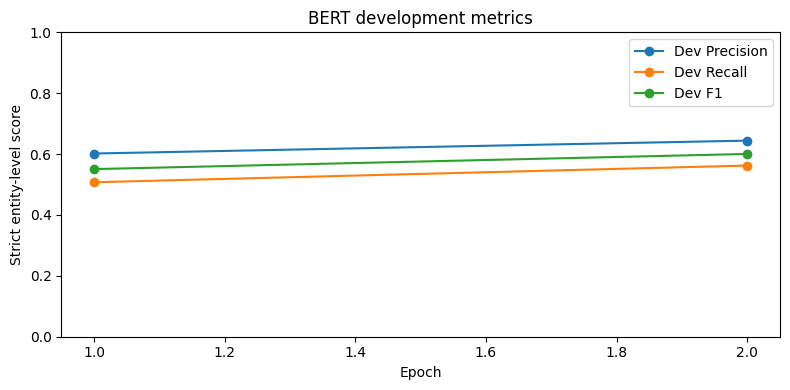

BERT test evaluation completed after dev-only epoch selection.


,Model,Representation,Architecture,Selection,Precision,Recall,F1
0,BERT multilingual cased,Contextual Transformer,BERT token classifier,Epoch 2 selected by dev F1=0.6005,0.5998,0.5223,0.5584


In [7]:
BERT_MODEL_NAME = 'bert-base-multilingual-cased'
BERT_LOCAL_PATH = ROOT / 'tp2_bert_model'
BERT_SOURCE = str(BERT_LOCAL_PATH) if (BERT_LOCAL_PATH / 'pytorch_model.bin').exists() else BERT_MODEL_NAME
BERT_MAX_LEN = 256
BERT_EPOCHS = 2
BERT_BATCH_SIZE = 4

tokenizer = AutoTokenizer.from_pretrained(BERT_SOURCE)

def encode_bert_split(sentences):
    encoded_rows = []
    for sentence in sentences:
        words = [token for token, _ in sentence]
        word_labels = [label2id[tag] for _, tag in sentence]
        encoding = tokenizer(words, is_split_into_words=True, truncation=True, padding='max_length', max_length=BERT_MAX_LEN)
        aligned_labels = []
        previous_word_id = None
        for word_id in encoding.word_ids():
            if word_id is None or word_id == previous_word_id or word_id >= len(word_labels):
                aligned_labels.append(-100)
            else:
                aligned_labels.append(word_labels[word_id])
            previous_word_id = word_id
        encoded_rows.append({
            'input_ids': torch.tensor(encoding['input_ids'], dtype=torch.long),
            'attention_mask': torch.tensor(encoding['attention_mask'], dtype=torch.long),
            'labels': torch.tensor(aligned_labels, dtype=torch.long),
        })
    return encoded_rows

class BERTNERDataset(Dataset):
    def __init__(self, rows):
        self.rows = rows

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        return self.rows[index]

bert_encoded = {split: encode_bert_split(sentences) for split, sentences in splits.items()}
bert_loaders = {
    split: DataLoader(BERTNERDataset(rows), batch_size=BERT_BATCH_SIZE, shuffle=(split == 'train'))
    for split, rows in bert_encoded.items()
}

def evaluate_bert(model, loader):
    model.eval()
    total_loss = 0.0
    true_sequences, pred_sequences = [], []
    with torch.no_grad():
        for batch in loader:
            batch = {key: value.to(DEVICE) for key, value in batch.items()}
            outputs = model(**batch)
            total_loss += outputs.loss.item()
            predictions = outputs.logits.argmax(dim=-1)
            for row in range(batch['labels'].size(0)):
                mask = batch['labels'][row] != -100
                true_sequences.append([id2label[int(value)] for value in batch['labels'][row][mask]])
                pred_sequences.append([id2label[int(value)] for value in predictions[row][mask]])
    metrics = seqeval_metrics(true_sequences, pred_sequences)
    metrics['Loss'] = total_loss / len(loader)
    return metrics, true_sequences, pred_sequences

bert_model = AutoModelForTokenClassification.from_pretrained(
    BERT_SOURCE,
    num_labels=len(label_names),
    id2label=id2label,
    label2id=label2id,
).to(DEVICE)
bert_optimizer = AdamW(bert_model.parameters(), lr=3e-5)
bert_history = []
best_bert_state, best_bert_dev = copy.deepcopy(bert_model.state_dict()), {'F1': -1.0}
for epoch in range(1, BERT_EPOCHS + 1):
    bert_model.train()
    train_loss = 0.0
    for batch in bert_loaders['train']:
        batch = {key: value.to(DEVICE) for key, value in batch.items()}
        bert_optimizer.zero_grad()
        outputs = bert_model(**batch)
        outputs.loss.backward()
        nn.utils.clip_grad_norm_(bert_model.parameters(), 1.0)
        bert_optimizer.step()
        train_loss += outputs.loss.item()
    bert_dev_metrics, _, _ = evaluate_bert(bert_model, bert_loaders['dev'])
    bert_history.append({'Epoch': epoch, 'Train loss': train_loss / len(bert_loaders['train']), **{f'Dev {key}': value for key, value in bert_dev_metrics.items()}})
    if bert_dev_metrics['F1'] > best_bert_dev['F1']:
        best_bert_dev = bert_dev_metrics
        best_bert_state = copy.deepcopy(bert_model.state_dict())

bert_model.load_state_dict(best_bert_state)
bert_history_df = pd.DataFrame(bert_history)
display(bert_history_df)
bert_history_df.plot(x='Epoch', y=['Dev Precision', 'Dev Recall', 'Dev F1'], marker='o', figsize=(8, 4), ylim=(0, 1))
plt.title('BERT development metrics')
plt.ylabel('Strict entity-level score')
plt.tight_layout()
plt.show()

bert_test_metrics, bert_true_sequences, bert_pred_sequences = evaluate_bert(bert_model, bert_loaders['test'])
bert_test_row = {
    'Model': 'BERT multilingual cased',
    'Representation': 'Contextual Transformer',
    'Architecture': 'BERT token classifier',
    'Selection': f"Epoch {int(bert_history_df.loc[bert_history_df['Dev F1'].idxmax(), 'Epoch'])} selected by dev F1={best_bert_dev['F1']:.4f}",
    'Precision': bert_test_metrics['Precision'],
    'Recall': bert_test_metrics['Recall'],
    'F1': bert_test_metrics['F1'],
}
print('BERT test evaluation completed after dev-only epoch selection.')
display(pd.DataFrame([bert_test_row]).style.format({'Precision': '{:.4f}', 'Recall': '{:.4f}', 'F1': '{:.4f}'}))

## 7. Final Seven-Model Comparison

,Model,Representation,Architecture,Selection,Precision,Recall,F1
0,BERT multilingual cased,Contextual Transformer,BERT token classifier,Epoch 2 selected by dev F1=0.6005,0.5998,0.5223,0.5584
1,Press FastText CBOW,FastText CBOW,CNN,CNN selected by dev F1=0.2666,0.3443,0.1757,0.2327
2,Press Word2Vec Skip-gram,Word2Vec Skip-gram,CNN,CNN selected by dev F1=0.2332,0.3440,0.1330,0.1918
3,Press Word2Vec CBOW,Word2Vec CBOW,CNN,CNN selected by dev F1=0.1954,0.2844,0.1167,0.1655
4,Medical Word2Vec Skip-gram,Word2Vec Skip-gram,CNN,CNN selected by dev F1=0.1086,0.1703,0.0633,0.0923
5,Medical FastText CBOW,FastText CBOW,CNN,CNN selected by dev F1=0.0037,0.0435,0.0010,0.0019
6,Medical Word2Vec CBOW,Word2Vec CBOW,CNN,CNN selected by dev F1=0.0005,0.2857,0.0005,0.0010


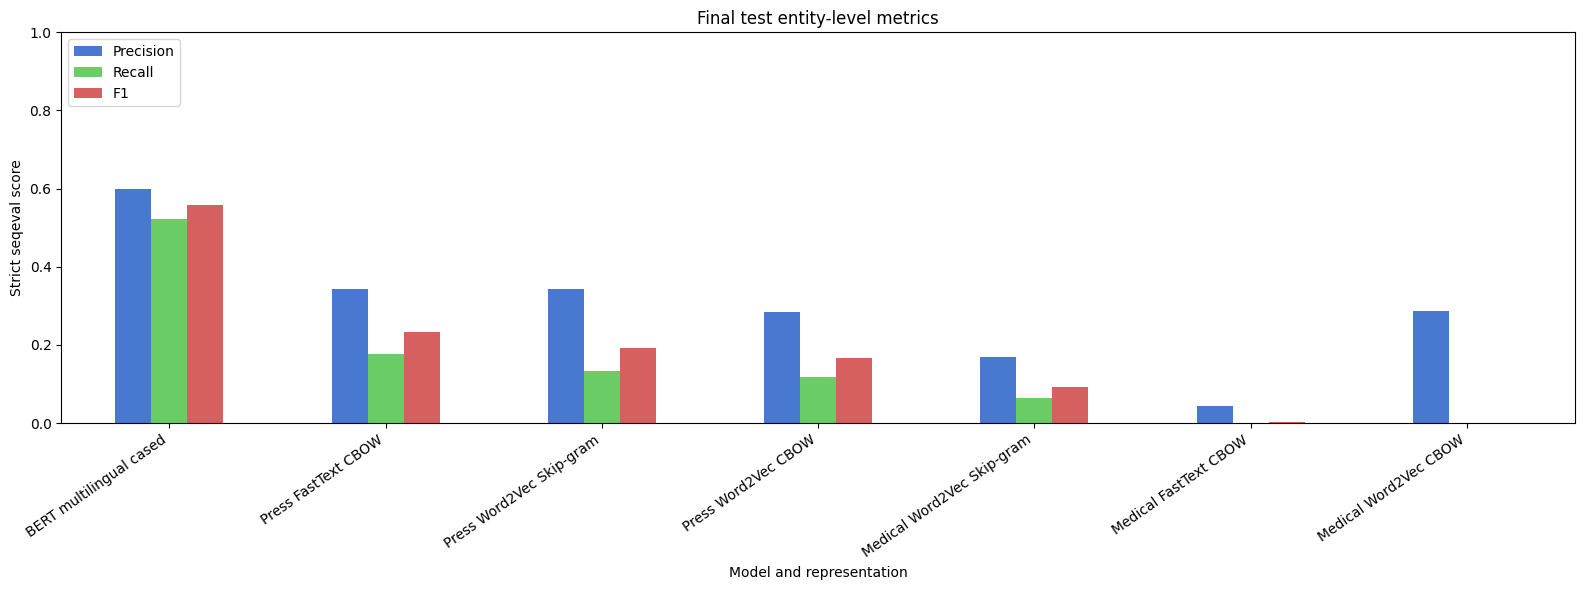

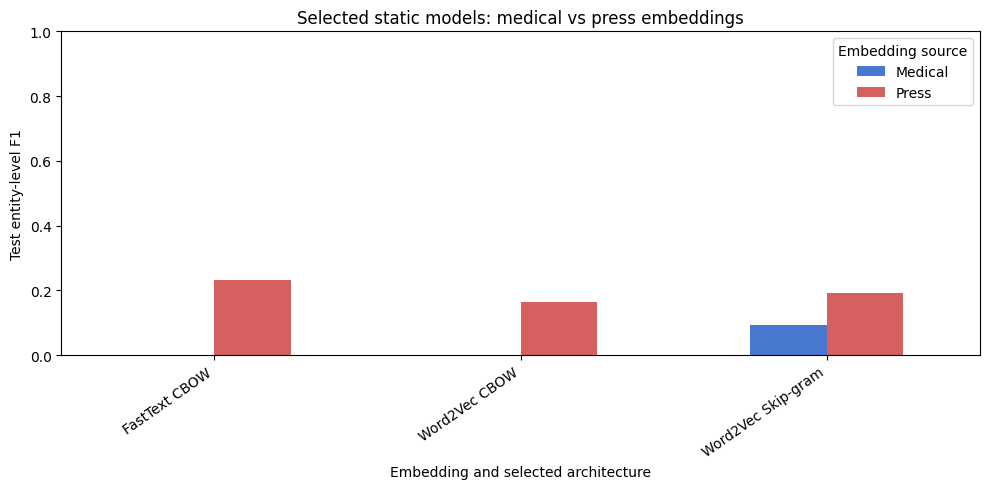

In [8]:
final_results = pd.concat([static_test_df, pd.DataFrame([bert_test_row])], ignore_index=True)
final_results = final_results.sort_values('F1', ascending=False).reset_index(drop=True)
display(final_results.style.format({'Precision': '{:.4f}', 'Recall': '{:.4f}', 'F1': '{:.4f}'}))

plot_df = final_results.set_index('Model')[['Precision', 'Recall', 'F1']]
plot_df.plot(kind='bar', figsize=(16, 6), color=['#4878CF', '#6ACC65', '#D65F5F'])
plt.title('Final test entity-level metrics')
plt.xlabel('Model and representation')
plt.ylabel('Strict seqeval score')
plt.ylim(0, 1)
plt.xticks(rotation=35, ha='right')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

static_plot = static_test_df.copy()
static_plot['Embedding source'] = static_plot['Model'].str.extract(r'^(Medical|Press)')
static_plot.pivot(index='Representation', columns='Embedding source', values='F1').plot(kind='bar', figsize=(10, 5), color=['#4878CF', '#D65F5F'])
plt.title('Selected static models: medical vs press embeddings')
plt.xlabel('Embedding and selected architecture')
plt.ylabel('Test entity-level F1')
plt.ylim(0, 1)
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

## 8. Entity-Type Comparison

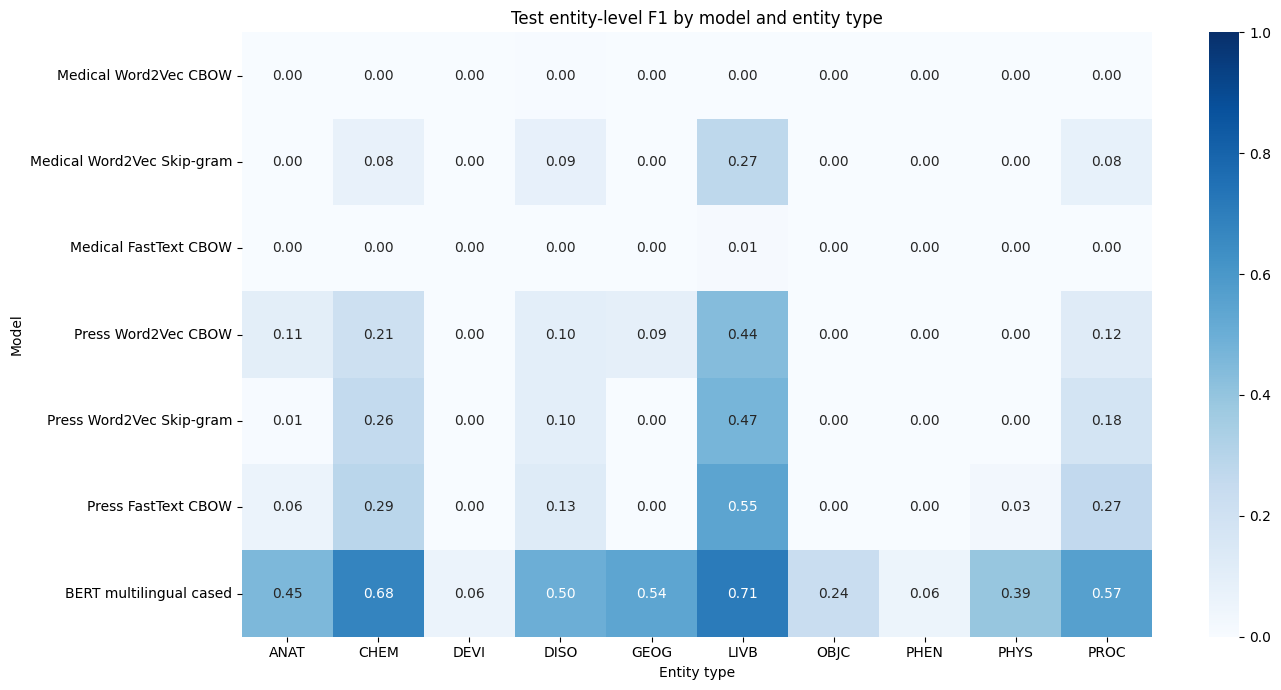

In [9]:
def entity_f1_report(true_sequences, pred_sequences):
    report = classification_report(true_sequences, pred_sequences, output_dict=True, mode='strict', scheme=IOB2, zero_division=0)
    return {entity: values['f1-score'] for entity, values in report.items() if entity not in {'micro avg', 'macro avg', 'weighted avg'}}

entity_scores = {}
for run in selected_static:
    true_sequences, pred_sequences = static_entity_reports[run['Embedding']]
    entity_scores[run['Embedding']] = entity_f1_report(true_sequences, pred_sequences)
entity_scores['BERT multilingual cased'] = entity_f1_report(bert_true_sequences, bert_pred_sequences)
entity_f1_df = pd.DataFrame(entity_scores).T
plt.figure(figsize=(14, 7))
sns.heatmap(entity_f1_df, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1)
plt.title('Test entity-level F1 by model and entity type')
plt.xlabel('Entity type')
plt.ylabel('Model')
plt.tight_layout()
plt.show()

## Result Analysis

The final table above reports strict entity-level precision, recall, and F1 on the medical test set. The six static rows use the architecture selected by development F1; the BERT row uses the best development epoch. Therefore, the test set is used only for the final comparison.

**(a) Best representation.** The best representation is the model with the highest test F1 in the final table. BERT provides contextual representations, while each static row combines a TP1 embedding with the selected LSTM or CNN encoder.

**(b) Medical versus press embeddings.** Compare the paired Medical and Press rows for Word2Vec CBOW, Word2Vec Skip-gram, and FastText CBOW. The higher F1 within each pair indicates which corpus transfers better to medical NER. Medical embeddings are expected to benefit from domain-specific contexts; FastText can reduce OOV damage through subword vectors.

**(c) Static versus contextual representations.** Static embeddings assign one vector to a word type, so the LSTM or CNN must infer context from neighboring tokens. BERT assigns context-dependent subword representations and can model long-range dependencies and unseen word forms. The final F1, precision, recall, and entity-type heatmap show whether that contextual advantage appears on this dataset.

These conclusions are based on strict BIO entity matching with `seqeval`, not token accuracy. Results also depend on the fixed seed, frozen TP1 embeddings, model capacity, training epochs, and the BERT checkpoint.